<a href="https://colab.research.google.com/github/gokulvasan1011/e-commerce_product_review/blob/main/e_commerce_product_review.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)

files.upload()                      # choose amazon.csv
df = pd.read_csv("amazon.csv")
print(df.shape)
print(df.isna().sum()[lambda s: s > 0])

Saving amazon.csv to amazon.csv
(1465, 16)
rating_count    2
dtype: int64


In [ ]:
# target: numeric rating; one row has a corrupted value "|" -> drop it
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
print("Rows with invalid rating:", df["rating"].isna().sum())
df = df.dropna(subset=["rating"]).reset_index(drop=True)

# numeric product features: strip ₹, commas, % and convert to numbers
for c in ["discounted_price", "actual_price"]:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(r"[₹,]", "", regex=True), errors="coerce")
df["discount_percentage"] = pd.to_numeric(df["discount_percentage"].astype(str).str.replace("%", ""), errors="coerce")
df["rating_count"] = pd.to_numeric(df["rating_count"].astype(str).str.replace(",", ""), errors="coerce")
df["rating_count"] = df["rating_count"].fillna(df["rating_count"].median())   # 2 missing values

# categorical feature
df["main_category"] = df["category"].str.split("|").str[0]

# review text cleaning
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"https?://\S+", " ", t)      # remove image links found inside reviews
    t = re.sub(r"[^a-z0-9\s]", " ", t)        # remove punctuation/symbols
    return re.sub(r"\s+", " ", t).strip()

df["text"] = (df["review_title"].fillna("") + " , " + df["review_content"].fillna("")).map(clean_text)

NUM_COLS = ["discounted_price", "actual_price", "discount_percentage", "rating_count"]
print(df[NUM_COLS + ["rating"]].describe().T[["mean", "std", "min", "max"]])
print("Remaining missing values:", df[NUM_COLS + ["text", "rating"]].isna().sum().sum())

Rows with invalid rating: 1
                             mean           std   min       max
discounted_price      3126.011906   6946.625442  39.0   77990.0
actual_price          5447.002923  10878.270001  39.0  139900.0
discount_percentage     47.713115     21.627422   0.0      94.0
rating_count         18289.441940  42739.607548   2.0  426973.0
rating                   4.096585      0.291674   2.0       5.0
Remaining missing values: 0


In [ ]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
print("Train:", len(train_df), " Test:", len(test_df))

def num_matrix(d):
    x = d[NUM_COLS].copy()
    for c in ["discounted_price", "actual_price", "rating_count"]:
        x[c] = np.log1p(x[c])                 # reduce skew
    return x

scaler = StandardScaler().fit(num_matrix(train_df))
top_cats = train_df["main_category"].value_counts().index[:3].tolist()
def cat_matrix(d):
    return np.stack([(d["main_category"] == c).astype(float).values for c in top_cats], axis=1)

def tab_features(d):
    return np.hstack([scaler.transform(num_matrix(d)), cat_matrix(d)]).astype("float32")

Xtab_tr, Xtab_te = tab_features(train_df), tab_features(test_df)
y_tr = train_df["rating"].values.astype("float32")
y_te = test_df["rating"].values.astype("float32")

Train: 1171  Test: 293


In [ ]:
VOCAB, MAXLEN = 10000, 300
tok = Tokenizer(num_words=VOCAB, oov_token="<OOV>")
tok.fit_on_texts(train_df["text"])            # fit on training text only

def encode(texts):
    return pad_sequences(tok.texts_to_sequences(texts),
                         maxlen=MAXLEN, padding="post", truncating="post")

Xtxt_tr, Xtxt_te = encode(train_df["text"]), encode(test_df["text"])
print("Vocabulary size:", len(tok.word_index))
print("Sample text   :", train_df["text"][0][:100])
print("Encoded (first 15 ids):", Xtxt_tr[0][:15])
print("Text tensor:", Xtxt_tr.shape, " Tabular tensor:", Xtab_tr.shape)

Vocabulary size: 12864
Sample text   : ok product 900 ma bast product a little family product not resturant not hotel heard to relief but n
Encoded (first 15 ids): [  94   11 2272 5436 3915   11   10  122  589   11   16 5437   16 4560
 1860]
Text tensor: (1171, 300)  Tabular tensor: (1171, 7)


In [ ]:
txt_in = layers.Input(shape=(MAXLEN,), name="review_tokens")
x = layers.Embedding(VOCAB, 64, mask_zero=True)(txt_in)
x = layers.Bidirectional(layers.GRU(64, return_sequences=True, dropout=0.2))(x)
x = layers.GlobalMaxPooling1D()(x)
x = layers.Dropout(0.4)(x)

tab_in = layers.Input(shape=(Xtab_tr.shape[1],), name="product_features")
t = layers.Dense(16, activation="relu")(tab_in)

h = layers.concatenate([x, t])
h = layers.Dense(32, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-3))(h)
h = layers.Dropout(0.3)(h)
out = layers.Dense(1, name="rating")(h)

model = models.Model([txt_in, tab_in], out)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="huber", metrics=["mae"])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:982: UserWarning: Layer 'global_max_pooling1d' (of type GlobalMaxPooling1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review_tokens       │ (None, 300)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 300, 64)   │    640,000 │ review_tokens[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 300)       │          0 │ review_tokens[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 300, 128)  │     49,920 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ bidirectional[0]… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ product_features    │ (None, 7)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        128 │ product_features… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 144)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      4,640 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rating (Dense)      │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 694,721 (2.65 MB)

 Trainable params: 694,721 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
33/33 - 27s - 819ms/step - loss: 0.0934 - mae: 0.2291 - val_loss: 0.0713 - val_mae: 0.1875
Epoch 2/30
33/33 - 14s - 422ms/step - loss: 0.0778 - mae: 0.2157 - val_loss: 0.0612 - val_mae: 0.1842
Epoch 3/30
33/33 - 18s - 533ms/step - loss: 0.0665 - mae: 0.2072 - val_loss: 0.0540 - val_mae: 0.1824
Epoch 4/30
33/33 - 18s - 555ms/step - loss: 0.0588 - mae: 0.2003 - val_loss: 0.0479 - val_mae: 0.1775
Epoch 5/30
33/33 - 14s - 421ms/step - loss: 0.0526 - mae: 0.1950 - val_loss: 0.0421 - val_mae: 0.1685
Epoch 6/30
33/33 - 14s - 426ms/step - loss: 0.0472 - mae: 0.1854 - val_loss: 0.0377 - val_mae: 0.1628
Epoch 7/30
33/33 - 14s - 429ms/step - loss: 0.0398 - mae: 0.1719 - val_loss: 0.0334 - val_mae: 0.1530
Epoch 8/30
33/33 - 20s - 618ms/step - loss: 0.0332 - mae: 0.1538 - val_loss: 0.0330 - val_mae: 0.1601
Epoch 9/30
33/33 - 21s - 635ms/step - loss: 0.0276 - mae: 0.1389 - val_loss: 0.0298 - val_mae: 0.1471
Epoch 10/30
33/33 - 21s - 644ms/step - loss: 0.0281 - mae: 0.1432 - val_loss: 0.02

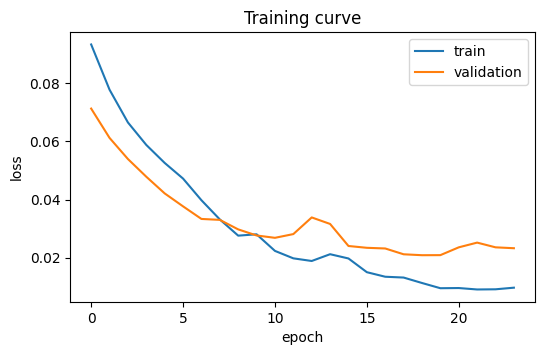

In [ ]:
y_mean = y_tr.mean()                           # centre the target so the model learns deviations
early = callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

hist = model.fit([Xtxt_tr, Xtab_tr], y_tr - y_mean,
                 validation_split=0.1, epochs=30, batch_size=32,
                 callbacks=[early], verbose=2)

plt.figure(figsize=(6, 3.5))
plt.plot(hist.history["loss"], label="train")
plt.plot(hist.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Training curve"); plt.show()

In [ ]:
pred = np.clip(model.predict([Xtxt_te, Xtab_te]).ravel() + y_mean, 1, 5)

mae  = mean_absolute_error(y_te, pred)
rmse = mean_squared_error(y_te, pred) ** 0.5
r2   = r2_score(y_te, pred)
base_mae  = mean_absolute_error(y_te, np.full_like(y_te, y_tr.mean()))
base_rmse = mean_squared_error(y_te, np.full_like(y_te, y_tr.mean())) ** 0.5

print(f"MAE  : {mae:.3f}   (always predict the mean: {base_mae:.3f})")
print(f"RMSE : {rmse:.3f}   (always predict the mean: {base_rmse:.3f})")
print(f"R^2  : {r2:.3f}")
print(f"Within +/-0.25 stars: {np.mean(np.abs(pred - y_te) <= 0.25) * 100:.1f}%")
print(f"Within +/-0.50 stars: {np.mean(np.abs(pred - y_te) <= 0.50) * 100:.1f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 139ms/step
MAE  : 0.164   (always predict the mean: 0.210)
RMSE : 0.238   (always predict the mean: 0.279)
R^2  : 0.268
Within +/-0.25 stars: 78.8%
Within +/-0.50 stars: 95.2%


,product,actual,predicted,abs_error
0,AMERICAN MICRONIC- Imported Wet & Dry Vacuum,4.2,4.22,0.02
1,Skadioo WiFi Adapter for pc | Car Accessories,3.7,3.97,0.27
2,LOHAYA Voice Assistant Remote Compatible for,3.3,3.34,0.04
3,POPIO Tempered Glass Screen Protector Compati,4.3,4.17,0.13
4,SWAPKART Fast Charging Cable and Data Sync US,3.9,4.33,0.43
5,ESR Screen Protector Compatible with iPad Pro,4.5,4.28,0.22
6,Ambrane 2 in 1 Type-C & Micro USB Cable with,4.1,4.11,0.01
7,D-Link DWA-131 300 Mbps Wireless Nano USB Ada,4.1,4.12,0.02
8,"AGARO Esteem Multi Kettle 1.2 Litre, 600W wit",4.2,4.12,0.08
9,"Libra Room Heater for Home, Room Heaters Home",3.6,4.14,0.54


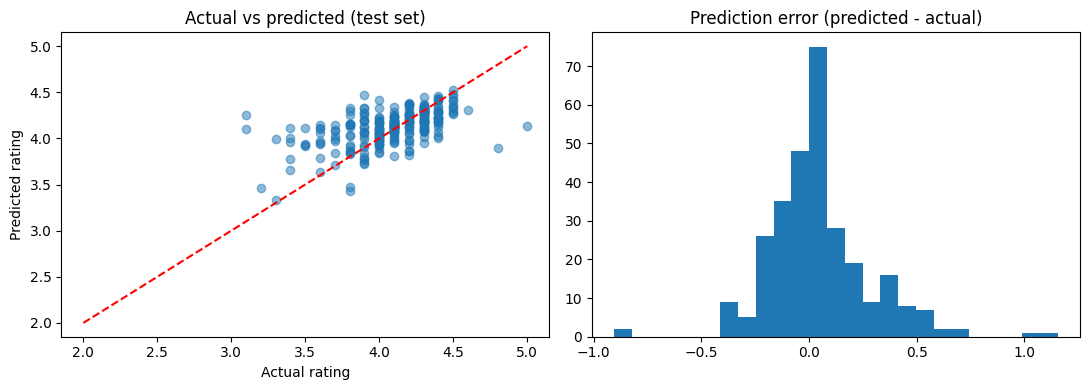

In [ ]:
cmp = pd.DataFrame({"product": test_df["product_name"].str[:45],
                    "actual": y_te, "predicted": pred.round(2),
                    "abs_error": np.abs(y_te - pred).round(2)})
display(cmp.head(15))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y_te, pred, alpha=0.5)
ax[0].plot([2, 5], [2, 5], "r--")
ax[0].set_xlabel("Actual rating"); ax[0].set_ylabel("Predicted rating")
ax[0].set_title("Actual vs predicted (test set)")
ax[1].hist(pred - y_te, bins=25); ax[1].set_title("Prediction error (predicted - actual)")
plt.tight_layout(); plt.show()

# New Section

In [ ]:
# Unseen reviews: product features are unknown, so training medians are used
med = train_df[NUM_COLS].median()
med_cat = train_df["main_category"].mode()[0]

def predict_rating(review_text, discounted_price=None, actual_price=None,
                   discount_percentage=None, rating_count=None, main_category=None):
    row = pd.DataFrame([{
        "discounted_price":    discounted_price    or med["discounted_price"],
        "actual_price":        actual_price        or med["actual_price"],
        "discount_percentage": discount_percentage or med["discount_percentage"],
        "rating_count":        rating_count        or med["rating_count"],
        "main_category":       main_category       or med_cat}])
    seq = encode([clean_text(review_text)])
    p = model.predict([seq, tab_features(row)], verbose=0).ravel()[0] + y_mean
    return float(np.clip(p, 1, 5))

unseen = [
    "Excellent product, works perfectly and the build quality is superb. Totally worth the money!",
    "Stopped working after two weeks. Very poor quality, waste of money. Do not buy.",
    "Average cable. Charges okay but gets hot sometimes. Value for money though.",
    "Fast delivery and easy to use, sound quality is great and battery lasts long.",
    "Terrible, the product arrived damaged and customer support never replied.",
]
for r in unseen:
    print(f"{predict_rating(r):.2f}  <-  {r}")

4.20  <-  Excellent product, works perfectly and the build quality is superb. Totally worth the money!
3.71  <-  Stopped working after two weeks. Very poor quality, waste of money. Do not buy.
4.00  <-  Average cable. Charges okay but gets hot sometimes. Value for money though.
4.18  <-  Fast delivery and easy to use, sound quality is great and battery lasts long.
4.23  <-  Terrible, the product arrived damaged and customer support never replied.


Classification accuracy (3 rating bands): 60.4%
Majority-class baseline                 : 42.3%


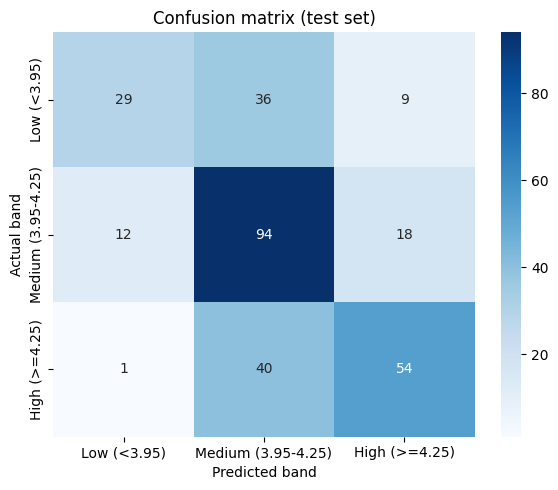

                    precision    recall  f1-score   support

       Low (<3.95)       0.69      0.39      0.50        74
Medium (3.95-4.25)       0.55      0.76      0.64       124
     High (>=4.25)       0.67      0.57      0.61        95

          accuracy                           0.60       293
         macro avg       0.64      0.57      0.58       293
      weighted avg       0.62      0.60      0.60       293



In [ ]:
import seaborn as sns
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

# convert ratings into 3 classes
bins   = [0, 3.95, 4.25, 5.1]
labels = ["Low (<3.95)", "Medium (3.95-4.25)", "High (>=4.25)"]

def to_class(r):
    return pd.cut(pd.Series(r), bins=bins, labels=labels, right=False)

y_true_cls = to_class(y_te)
y_pred_cls = to_class(pred)

# accuracy
acc = accuracy_score(y_true_cls, y_pred_cls)
print(f"Classification accuracy (3 rating bands): {acc * 100:.1f}%")
print(f"Majority-class baseline                 : {y_true_cls.value_counts(normalize=True).max() * 100:.1f}%")

# confusion matrix
cm = confusion_matrix(y_true_cls, y_pred_cls, labels=labels)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted band"); plt.ylabel("Actual band")
plt.title("Confusion matrix (test set)")
plt.tight_layout(); plt.show()

# precision, recall and F1 per class
print(classification_report(y_true_cls, y_pred_cls, labels=labels, zero_division=0))

In [ ]:
!pip -q install vaderSentiment
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
sia = SentimentIntensityAnalyzer()

def sentiment_feats(raw):
    parts = [p for p in str(raw).split(",") if p.strip() and "http" not in p]
    s = [sia.polarity_scores(p)["compound"] for p in parts] or [0.0]
    return pd.Series({"sent_mean": np.mean(s), "sent_min": np.min(s),
                      "sent_neg_share": np.mean(np.array(s) < 0), "n_reviews": len(parts)})

df = pd.concat([df, df["review_content"].apply(sentiment_feats)], axis=1)
NUM_COLS = NUM_COLS + ["sent_mean", "sent_min", "sent_neg_share", "n_reviews"]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 3.3 MB/s eta 0:00:00
